# Winter Storm Uri (2021) vs. Winter Storm Fern (2026)

How did flight operations at DFW, IAH, AUS and SAT respond to the two storms?

This notebook only reads the dbt marts (`mart_storm_summary`, `mart_airport_hourly`,
`mart_flights_weather`). Build them first: `cd dbt && dbt seed && dbt build`.
Charts are saved to `docs/images/` for the README.

In [71]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd


def find_project_root(start: Path) -> Path:
    # The notebook may run from analysis/ or from the repository root.
    for folder in [start, *start.parents]:
        if (folder / "dbt" / "dbt_project.yml").exists():
            return folder
    raise FileNotFoundError("Project root with dbt/dbt_project.yml not found")


ROOT = find_project_root(Path.cwd())
DB_PATH = ROOT / "data" / "warehouse.duckdb"
IMAGES = ROOT / "docs" / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

EVENTS = {"uri_2021": "Uri, Feb 2021", "fern_2026": "Fern, Jan 2026"}
COLORS = {"uri_2021": "#1f4e79", "fern_2026": "#e07b39"}
AIRPORTS = ["DFW", "AUS", "SAT", "IAH"]
MIN_DEPARTURES = 3  # same threshold as in the marts: quieter hours give noisy rates

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})


def query(sql: str) -> pd.DataFrame:
    # Read-only and closed right away, so dbt can write to the database afterwards.
    with duckdb.connect(str(DB_PATH), read_only=True) as con:
        df = con.sql(sql).df()
    # Nullable integer columns (NULL -> pd.NA) break matplotlib; plain floats use NaN instead.
    for col in df.columns:
        if pd.api.types.is_integer_dtype(df[col]) and df[col].isna().any():
            df[col] = df[col].astype("float64")
    return df


def save(fig, name: str) -> None:
    fig.savefig(IMAGES / name, dpi=150, bbox_inches="tight")

## 1. Storm summary

One row per storm and airport. `lag_from_sustained_h` counts hours from the start of
sustained winter precipitation (6+ consecutive hours) to the first hour with 50 %+ of
departures cancelled; negative values mean cancellations started before the storm.

In [72]:
summary = query('''
    SELECT event_id, airport_code,
           storm_onset, sustained_onset, precip_end,
           winter_precip_hours, freezing_rain_hours, ice_pellets_hours, snow_hours,
           min_temp_c,
           lag_from_sustained_h, recovery_h,
           pre_onset_cancel_rate, disruption_cancel_rate, weather_reason_share
    FROM mart_storm_summary
''')
summary["storm"] = summary["event_id"].map(EVENTS)
summary["airport_code"] = pd.Categorical(summary["airport_code"], AIRPORTS, ordered=True)
summary = summary.sort_values(["airport_code", "event_id"], ascending=[True, False])

summary.set_index(["airport_code", "storm"]).drop(columns="event_id").style.format({
    "min_temp_c": "{:.1f}",
    "lag_from_sustained_h": "{:.0f}",
    "recovery_h": "{:.0f}",
    "pre_onset_cancel_rate": "{:.0%}",
    "disruption_cancel_rate": "{:.0%}",
    "weather_reason_share": "{:.0%}",
}, na_rep="—")

## 2. Cancellations around the storm, hour by hour

Hour 0 is the start of sustained winter precipitation at each airport (the storm onset
when no 6-hour run exists, as for IAH during Fern). Departures are grouped into 3-hour
bins, which smooths out quiet hours; bins with fewer than three scheduled departures are
left blank.

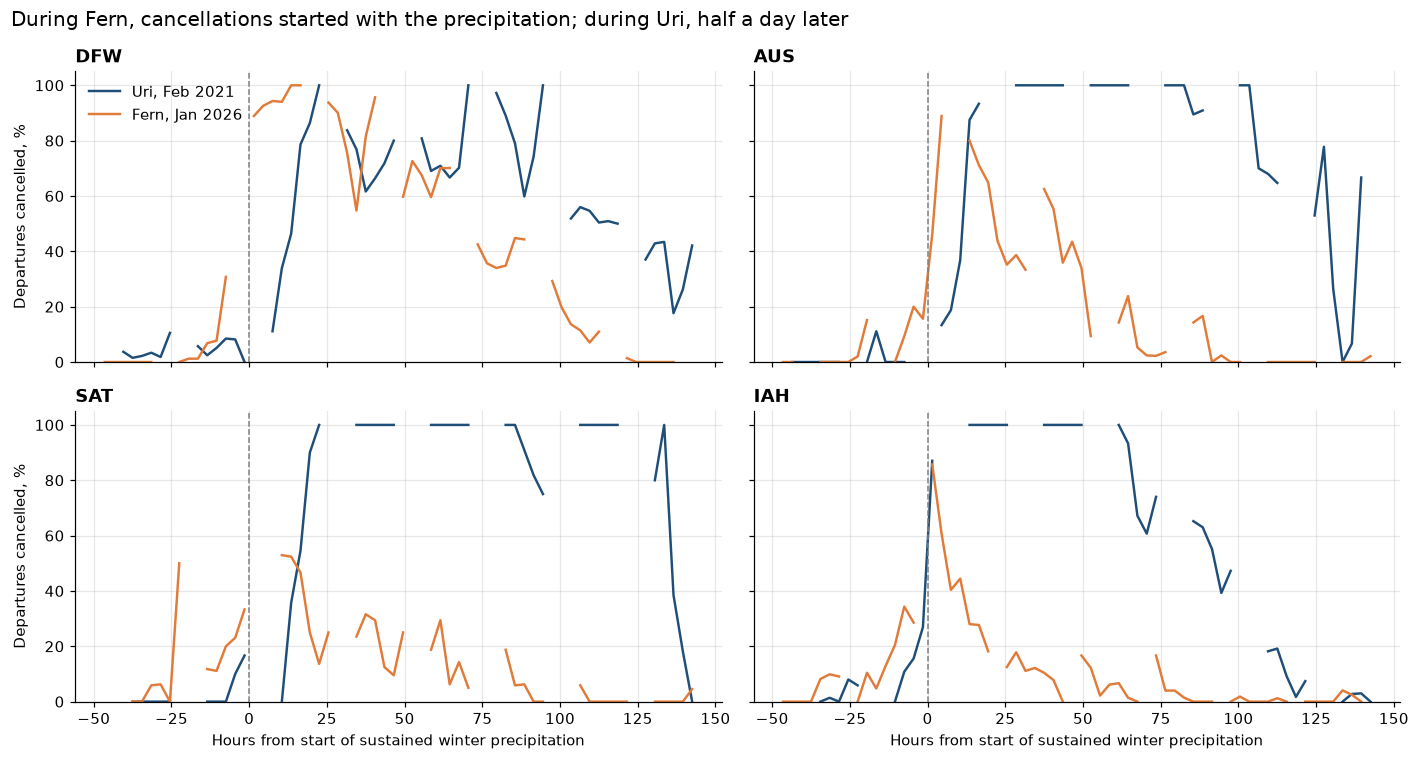

In [73]:
hourly = query('''
    SELECT h.event_id, h.airport_code, h.weather_hour,
           h.scheduled_departures, h.cancelled, h.has_winter_precip, h.temp_c,
           datediff('hour', coalesce(s.sustained_onset, s.storm_onset), h.weather_hour)
               AS hours_from_onset
    FROM mart_airport_hourly AS h
    JOIN mart_storm_summary AS s USING (event_id, airport_code)
    WHERE s.storm_onset IS NOT NULL
''')
window = hourly[hourly["hours_from_onset"].between(-48, 143)].copy()
window["bin_start"] = (window["hours_from_onset"] // 3) * 3

BIN = 3
binned = (window
          .groupby(["event_id", "airport_code", "bin_start"], as_index=False)
          .agg(scheduled=("scheduled_departures", "sum"), cancelled=("cancelled", "sum")))
# Blank instead of drop: the line breaks rather than bridging an empty bin with a straight segment.
binned["rate_pct"] = (100 * binned["cancelled"] / binned["scheduled"]).where(
    binned["scheduled"] >= MIN_DEPARTURES)
binned["bin_mid"] = binned["bin_start"] + BIN / 2

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
for ax, airport in zip(axes.flat, AIRPORTS):
    for event_id, label in EVENTS.items():
        data = binned[(binned["airport_code"] == airport) & (binned["event_id"] == event_id)]
        ax.plot(data["bin_mid"], data["rate_pct"],
                color=COLORS[event_id], label=label, linewidth=1.6)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(airport, loc="left", fontweight="bold")
    ax.set_ylim(0, 105)
for ax in axes[1]:
    ax.set_xlabel("Hours from start of sustained winter precipitation")
for ax in axes[:, 0]:
    ax.set_ylabel("Departures cancelled, %")
axes[0, 0].legend(frameon=False)
fig.suptitle("During Fern, cancellations started with the precipitation; during Uri, half a day later",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save(fig, "cancellations_around_onset.png")
plt.show()

## 3. Reaction and recovery

Lag: hours from sustained precipitation to mass cancellations (50 %+ of departures).
Recovery: hours from the end of winter precipitation until cancellations stayed below 10 %
for six busy hours in a row. "n/a": no sustained (6+ hour) winter precipitation, as at IAH
during Fern.

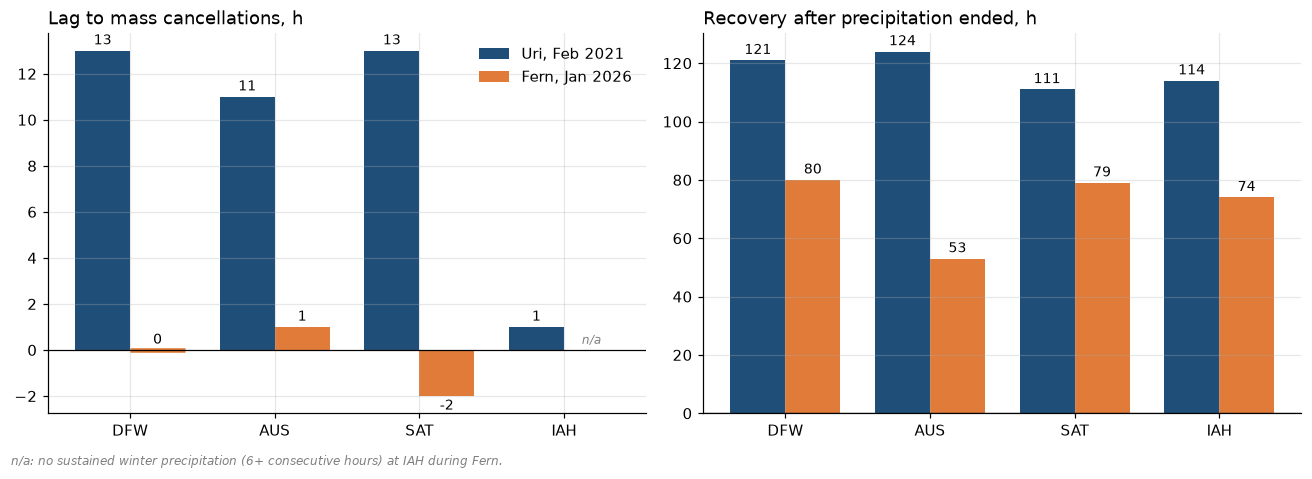

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
metrics = [("lag_from_sustained_h", "Lag to mass cancellations, h"),
           ("recovery_h", "Recovery after precipitation ended, h")]
width = 0.38
for ax, (column, title) in zip(axes, metrics):
    for i, (event_id, label) in enumerate(EVENTS.items()):
        data = summary[summary["event_id"] == event_id].set_index("airport_code").reindex(AIRPORTS)
        x = [j + (i - 0.5) * width for j in range(len(AIRPORTS))]
        values = data[column].astype("float64")
        bars = ax.bar(x, values.fillna(0), width, color=COLORS[event_id], label=label)
        ax.bar_label(bars, labels=["" if pd.isna(v) else f"{v:.0f}" for v in values],
                     padding=2, fontsize=9)
        for xi, v in zip(x, values):
            if pd.isna(v):
                # Missing is not zero: grey italic note instead of a value label.
                ax.annotate("n/a", (xi, 0), xytext=(0, 4), textcoords="offset points",
                            ha="center", fontsize=8, color="grey", style="italic")
            elif v == 0:
                # A zero-height bar is invisible; draw a thin line so "0" has a bar under it.
                ax.hlines(0, xi - width / 2, xi + width / 2, colors=COLORS[event_id], linewidth=3)
    ax.set_xticks(range(len(AIRPORTS)), AIRPORTS)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title, loc="left")
axes[0].legend(frameon=False)
fig.text(0.01, -0.02, "n/a: no sustained winter precipitation (6+ consecutive hours) at IAH during Fern.",
         fontsize=8, color="grey", style="italic")
fig.tight_layout()
save(fig, "lag_and_recovery.png")
plt.show()

## 4. Which weather cancels flights?

Cancellation rate by the weather observed at the origin airport in the hour of the
scheduled departure, over the whole data window of each storm (January–February).

Most cancellations in both storms fell in hours without falling precipitation: before the
storm (cancelled in advance) or after it (ice on the ground, extreme cold). METAR codes
describe only precipitation that is falling, not snow or ice lying on the runways.

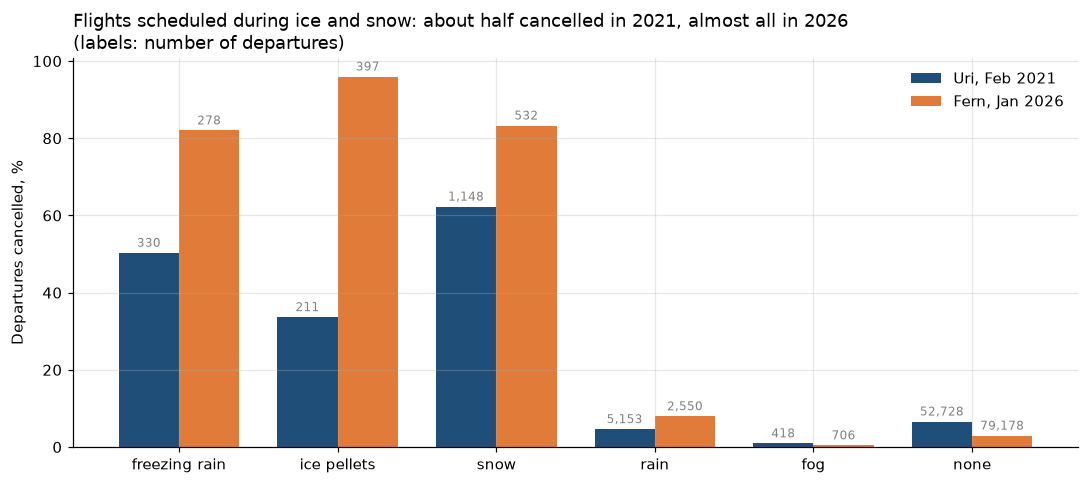

departures          cancellation_rate          
event_id       fern_2026 uri_2021         fern_2026  uri_2021
weather_group                                                
freezing_rain      278.0    330.0          0.820144  0.503030
ice_pellets        397.0    211.0          0.959698  0.336493
snow               532.0   1148.0          0.832707  0.622822
rain              2550.0   5153.0          0.079608  0.046187
fog                706.0    418.0          0.004249  0.009569
none             79178.0  52728.0          0.029377  0.065999

In [75]:
GROUP_ORDER = ["freezing_rain", "ice_pellets", "snow", "rain", "fog", "none"]
by_weather = query('''
    SELECT event_id, weather_group,
           count(*) AS departures,
           avg(is_cancelled::int) AS cancellation_rate
    FROM mart_flights_weather
    WHERE weather_group IS NOT NULL
    GROUP BY ALL
''')

fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.38
for i, (event_id, label) in enumerate(EVENTS.items()):
    data = by_weather[by_weather["event_id"] == event_id].set_index("weather_group").reindex(GROUP_ORDER)
    x = [j + (i - 0.5) * width for j in range(len(GROUP_ORDER))]
    bars = ax.bar(x, data["cancellation_rate"].astype("float64") * 100, width, color=COLORS[event_id], label=label)
    ax.bar_label(bars, labels=[f"{n:,.0f}" if pd.notna(n) else "" for n in data["departures"]],
                 padding=2, fontsize=8, color="grey")
ax.set_xticks(range(len(GROUP_ORDER)), [g.replace("_", " ") for g in GROUP_ORDER])
ax.set_ylabel("Departures cancelled, %")
ax.set_title("Flights scheduled during ice and snow: about half cancelled in 2021, almost all in 2026\n"
             "(labels: number of departures)", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "cancellations_by_weather.png")
plt.show()

by_weather.pivot(index="weather_group", columns="event_id", values=["departures", "cancellation_rate"]).reindex(GROUP_ORDER)

## 5. DFW: comparable storms, different response

DFW is the fairest comparison: both storms brought about 35 hours of winter precipitation.
Shaded hours had freezing rain, ice pellets or snow.

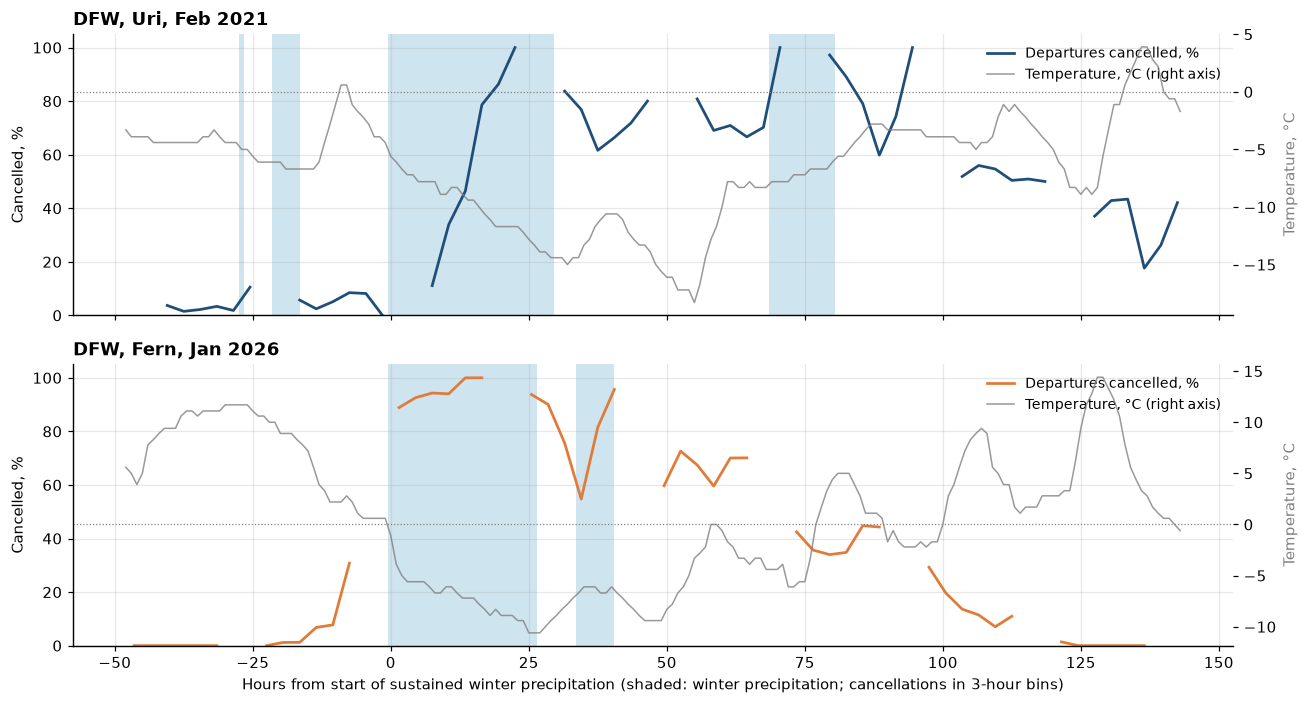

In [76]:
dfw = window[window["airport_code"] == "DFW"]
dfw_binned = binned[binned["airport_code"] == "DFW"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, (event_id, label) in zip(axes, EVENTS.items()):
    data = dfw[dfw["event_id"] == event_id].sort_values("hours_from_onset")
    for hour in data.loc[data["has_winter_precip"].fillna(False).astype(bool), "hours_from_onset"]:
        ax.axvspan(hour - 0.5, hour + 0.5, color="#9ecae1", alpha=0.5, linewidth=0)
    rates = dfw_binned[dfw_binned["event_id"] == event_id]
    ax.plot(rates["bin_mid"], rates["rate_pct"],
            color=COLORS[event_id], linewidth=1.8, label="Departures cancelled, %")
    ax.set_ylim(0, 105)
    ax.set_ylabel("Cancelled, %")
    ax.set_title(f"DFW, {label}", loc="left", fontweight="bold")

    temp_ax = ax.twinx()
    temp_ax.plot(data["hours_from_onset"], data["temp_c"], color="grey", linewidth=1, alpha=0.8,
                 label="Temperature, °C (right axis)")
    temp_ax.axhline(0, color="grey", linestyle=":", linewidth=0.8)
    temp_ax.set_ylabel("Temperature, °C", color="grey")
    temp_ax.grid(False)
    # one legend for both axes
    handles = ax.get_legend_handles_labels()[0] + temp_ax.get_legend_handles_labels()[0]
    ax.legend(handles, [h.get_label() for h in handles], loc="upper right", frameon=False, fontsize=9)
axes[-1].set_xlabel("Hours from start of sustained winter precipitation "
                    "(shaded: winter precipitation; cancellations in 3-hour bins)")
fig.tight_layout()
save(fig, "dfw_timeline.png")
plt.show()

## 6. Did the airports keep operating in ice and snow?

After Uri, Austin-Bergstrom bought dedicated snow removal equipment to keep at least one of its
two runways open ([City of Austin](https://www.austintexas.gov/blog/winter-weather-preparations-aus)),
and since December 2023 Houston Airports has contracted a company to operate snowplows and
other heavy machinery at IAH ([Houston Airports](https://www.fly2houston.com/airport-business/newsroom/press-releases/item/houstons-airports-prepare-for-extreme-winter-weather/)).
Airports clear runways, taxiways and roads; de-icing the aircraft is done by the airlines.

If the airfield worked better, it should show up in the flights that *did* operate during winter
hours and in how often departures kept going at all:

- **Extra taxi-out:** median taxi-out time of operated departures in winter hours minus the median
  in normal hours (no weather phenomena) at the same airport in the same data window. Taxi-out
  includes waiting for aircraft de-icing, so it reflects the airport and the airlines together.
- **Extra departure delay:** the same comparison for the average departure delay.
- **Winter hours with departures:** share of winter hours with 3+ scheduled departures in which
  at least one flight actually left.

AUS and IAH invested in equipment; DFW and SAT serve as a comparison.

In [77]:
airport_ops = query('''
    SELECT event_id,
           origin_airport AS airport_code,
           CASE WHEN has_winter_precip THEN 'winter' ELSE 'normal' END AS conditions,
           count(*)               AS operated_departures,
           median(taxi_out_min)   AS median_taxi_out_min,
           median(dep_delay_min)  AS median_dep_delay_min
    FROM mart_flights_weather
    WHERE NOT is_cancelled
      AND (has_winter_precip OR weather_group = 'none')
    GROUP BY ALL
''')

ops = airport_ops.pivot_table(
    index=["airport_code", "event_id"], columns="conditions",
    values=["operated_departures", "median_taxi_out_min", "median_dep_delay_min"])
ops.columns = [f"{value}_{condition}" for value, condition in ops.columns]
ops = ops.reset_index()
ops["extra_taxi_out_min"] = ops["median_taxi_out_min_winter"] - ops["median_taxi_out_min_normal"]
ops["extra_dep_delay_min"] = ops["median_dep_delay_min_winter"] - ops["median_dep_delay_min_normal"]

winter_hours = query('''
    SELECT event_id, airport_code,
           count(*)                                                  AS busy_winter_hours,
           count(*) FILTER (WHERE scheduled_departures > cancelled)  AS winter_hours_with_departures
    FROM mart_airport_hourly
    WHERE has_winter_precip AND scheduled_departures >= 3
    GROUP BY ALL
''')
winter_hours["share_hours_with_departures"] = (
    winter_hours["winter_hours_with_departures"] / winter_hours["busy_winter_hours"])

ops = ops.merge(winter_hours, on=["event_id", "airport_code"], how="left")
ops["storm"] = ops["event_id"].map(EVENTS)
ops["airport_code"] = pd.Categorical(ops["airport_code"], AIRPORTS, ordered=True)
ops = ops.sort_values(["airport_code", "event_id"], ascending=[True, False])

columns = ["airport_code", "storm", "operated_departures_winter",
           "median_taxi_out_min_normal", "median_taxi_out_min_winter", "extra_taxi_out_min",
           "extra_dep_delay_min", "busy_winter_hours", "share_hours_with_departures"]
ops[columns].set_index(["airport_code", "storm"]).style.format({
    "operated_departures_winter": "{:.0f}",
    "median_taxi_out_min_normal": "{:.0f}",
    "median_taxi_out_min_winter": "{:.0f}",
    "extra_taxi_out_min": "{:+.0f}",
    "extra_dep_delay_min": "{:+.0f}",
    "busy_winter_hours": "{:.0f}",
    "share_hours_with_departures": "{:.0%}",
}, na_rep="—")

Sample sizes matter here: during Fern most flights in winter hours were cancelled, so the
taxi-out and delay comparison rests on few operated departures (`operated_departures_winter`).
Treat differences of a few minutes as noise.

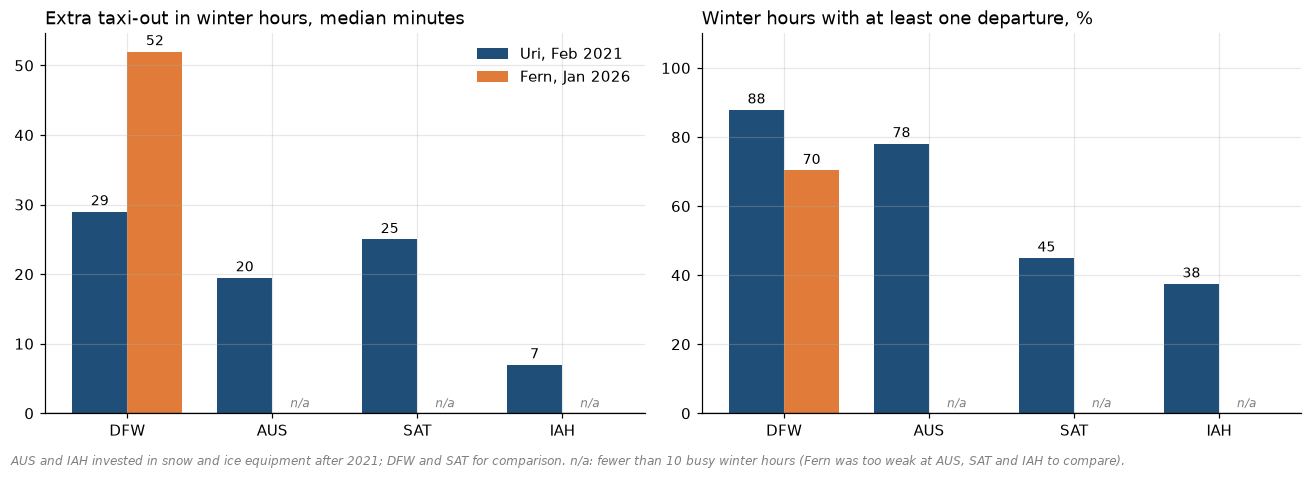

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
panels = [("extra_taxi_out_min", "Extra taxi-out in winter hours, median minutes"),
          ("share_hours_with_departures", "Winter hours with at least one departure, %")]
width = 0.38
MIN_WINTER_HOURS = 10  # fewer busy winter hours: too little data to compare
for ax, (column, title) in zip(axes, panels):
    for i, (event_id, label) in enumerate(EVENTS.items()):
        data = ops[ops["event_id"] == event_id].set_index("airport_code").reindex(AIRPORTS)
        values = data[column].astype("float64")
        values = values.where(data["busy_winter_hours"].fillna(0) >= MIN_WINTER_HOURS)
        if column.startswith("share"):
            values = values * 100
        x = [j + (i - 0.5) * width for j in range(len(AIRPORTS))]
        bars = ax.bar(x, values.fillna(0), width, color=COLORS[event_id], label=label)
        ax.bar_label(bars, labels=["" if pd.isna(v) else f"{v:.0f}" for v in values],
                     padding=2, fontsize=9)
        for xi, v in zip(x, values):
            if pd.isna(v):
                ax.annotate("n/a", (xi, 0), xytext=(0, 4), textcoords="offset points",
                            ha="center", fontsize=8, color="grey", style="italic")
            elif v == 0:
                ax.hlines(0, xi - width / 2, xi + width / 2, colors=COLORS[event_id], linewidth=3)
    ax.set_xticks(range(len(AIRPORTS)), AIRPORTS)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title, loc="left")
axes[1].set_ylim(0, 110)
axes[0].legend(frameon=False)
fig.text(0.01, -0.02,
         "AUS and IAH invested in snow and ice equipment after 2021; DFW and SAT for comparison. "
         "n/a: fewer than 10 busy winter hours (Fern was too weak at AUS, SAT and IAH to compare).",
         fontsize=8, color="grey", style="italic")
fig.tight_layout()
save(fig, "airport_operations_in_winter_hours.png")
plt.show()

**Result: the data cannot confirm that the new equipment helped.** Fern brought only 4 busy
winter hours to AUS and SAT and one to IAH, too few to compare. At DFW, the only airport with
comparable weather in both storms, fewer winter hours kept departures going during Fern
(70 % vs. 88 %), and the flights that did operate taxied longer (+52 vs. +29 minutes over normal)
and left much later (median extra delay +126 vs. +10 minutes). Flights are matched to their
scheduled hour, so many of them left after the precipitation had ended. This fits the airlines'
cancel-in-advance strategy rather than a better-run airfield: during Uri the flights that went
left roughly on time; during Fern fewer flights went, and those that did waited hours.

## 7. Did all airlines change their strategy, or only some?

Section 2 showed that during Fern cancellations came with the precipitation or before it.
Here the same question is asked per airline: who cancelled in advance, and who kept flying
into the storm?

BTS reports the **operating** carrier, so regional flights appear under their own codes.
Carriers that fly for one brand are grouped with it: American with Envoy (MQ) and PSA (OH),
Delta with Endeavor (9E), United with CommuteAir (C5) and ExpressJet (EV). Regionals flying for
several brands (SkyWest, Republic, Mesa) and smaller airlines are grouped as "Other".

Periods, per airport and storm:
- **before:** 24 hours before the start of sustained winter precipitation (as in section 2);
- **during:** from that start to the end of winter precipitation.

Rates based on fewer than 30 departures are not shown.

Coverage is uneven: Southwest serves Dallas and Houston mainly from Love Field and Hobby,
which are not part of this project, and United's hub IAH saw only 3 winter hours during Fern.
DFW, with comparable weather in both storms, is the fair comparison.

In [79]:
needed = {"event_id", "origin_airport", "airline_code", "scheduled_dep_hour", "is_cancelled",
          "cancellation_code", "has_winter_precip", "weather_group", "dep_delay_min", "taxi_out_min"}
missing = needed - set(query("DESCRIBE mart_flights_weather")["column_name"])
assert not missing, f"mart_flights_weather has no columns: {sorted(missing)}"

AIRLINE_GROUPS = {
    "AA": "American", "MQ": "American", "OH": "American",
    "WN": "Southwest",
    "UA": "United", "C5": "United", "EV": "United",
    "DL": "Delta", "9E": "Delta",
    "NK": "Spirit", "F9": "Frontier",
}
MIN_AIRLINE_DEPARTURES = 30

window_flights = query('''
    WITH bounds AS (
        SELECT event_id, airport_code,
               coalesce(sustained_onset, storm_onset) AS onset,
               precip_end
        FROM mart_storm_summary
        WHERE storm_onset IS NOT NULL
    )
    SELECT f.event_id,
           f.origin_airport AS airport_code,
           f.airline_code,
           f.is_cancelled,
           f.cancellation_code,
           f.scheduled_dep_hour < b.onset AS is_before
    FROM mart_flights_weather AS f
    JOIN bounds AS b
      ON f.event_id = b.event_id AND f.origin_airport = b.airport_code
    WHERE f.scheduled_dep_hour >= b.onset - INTERVAL 24 HOUR
      AND f.scheduled_dep_hour <= b.precip_end
''')
window_flights["airline_group"] = window_flights["airline_code"].map(AIRLINE_GROUPS).fillna("Other")


def cancellation_rates(df: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    df = df.assign(
        cancelled_before=df["is_cancelled"] & df["is_before"],
        cancelled_during=df["is_cancelled"] & ~df["is_before"],
        cancelled_weather=df["is_cancelled"] & df["cancellation_code"].eq("B"),
    )
    out = df.groupby(keys, as_index=False).agg(
        departures=("is_before", "size"),
        departures_before=("is_before", "sum"),
        cancelled=("is_cancelled", "sum"),
        cancelled_before=("cancelled_before", "sum"),
        cancelled_during=("cancelled_during", "sum"),
        cancelled_weather=("cancelled_weather", "sum"),
    )
    out["departures_during"] = out["departures"] - out["departures_before"]
    out["cancel_rate_before"] = (out["cancelled_before"] / out["departures_before"]).where(
        out["departures_before"] >= MIN_AIRLINE_DEPARTURES)
    out["cancel_rate_during"] = (out["cancelled_during"] / out["departures_during"]).where(
        out["departures_during"] >= MIN_AIRLINE_DEPARTURES)
    # share of cancellations the airline attributed to weather (code B)
    out["weather_reason_share"] = (out["cancelled_weather"] / out["cancelled"]).where(out["cancelled"] >= 10)
    return out


by_airport = cancellation_rates(window_flights, ["airport_code", "airline_group", "event_id"])
by_airport["storm"] = by_airport["event_id"].map(EVENTS)

metrics = ["departures_during", "cancel_rate_before", "cancel_rate_during"]
storms = list(EVENTS.values())
# keep airline groups with enough departures during the precipitation in at least one storm
enough = by_airport.groupby(["airport_code", "airline_group"])["departures_during"].transform("max") \
    >= MIN_AIRLINE_DEPARTURES
table = (by_airport[enough]
         .pivot_table(index=["airport_code", "airline_group"], columns="storm", values=metrics)
         .reindex(columns=pd.MultiIndex.from_product([metrics, storms]))
         .reindex(AIRPORTS, level=0))
table.style.format(
    {col: ("{:.0f}" if col[0] == "departures_during" else "{:.0%}") for col in table.columns},
    na_rep="—")

Airlines attributed 95–100 % of their cancellations to weather (code B) in both storms, so
cancellation reasons do not distinguish strategies and are left out. AUS and SAT drop out of the
table: during Fern no airline had 30+ departures there in the precipitation period.

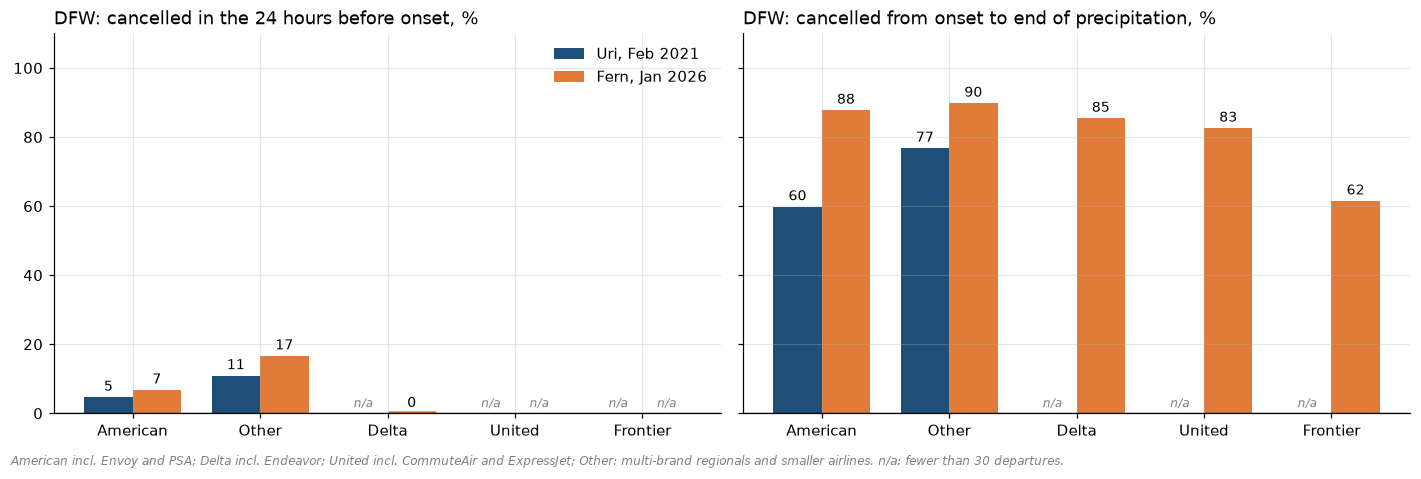

In [80]:
def grouped_bars(ax, frame, column, categories, scale=1.0):
    # Uri and Fern side by side for each category; missing values labelled n/a, not drawn as zero.
    width = 0.38
    for i, (event_id, label) in enumerate(EVENTS.items()):
        data = frame[frame["event_id"] == event_id].set_index(frame.index.name or "airline_group")
        values = data.reindex(categories)[column].astype("float64") * scale
        x = [j + (i - 0.5) * width for j in range(len(categories))]
        bars = ax.bar(x, values.fillna(0), width, color=COLORS[event_id], label=label)
        ax.bar_label(bars, labels=["" if pd.isna(v) else f"{v:.0f}" for v in values],
                     padding=2, fontsize=9)
        for xi, v in zip(x, values):
            if pd.isna(v):
                ax.annotate("n/a", (xi, 0), xytext=(0, 4), textcoords="offset points",
                            ha="center", fontsize=8, color="grey", style="italic")
            elif v == 0:
                ax.hlines(0, xi - width / 2, xi + width / 2, colors=COLORS[event_id], linewidth=3)
    ax.set_xticks(range(len(categories)), categories)
    ax.axhline(0, color="black", linewidth=0.8)


dfw_rates = by_airport[by_airport["airport_code"] == "DFW"]
dfw_groups = (dfw_rates[dfw_rates["departures_during"] >= MIN_AIRLINE_DEPARTURES]
              .groupby("airline_group")["departures"].sum()
              .sort_values(ascending=False).index.tolist())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
panels = [("cancel_rate_before", "DFW: cancelled in the 24 hours before onset, %"),
          ("cancel_rate_during", "DFW: cancelled from onset to end of precipitation, %")]
for ax, (column, title) in zip(axes, panels):
    grouped_bars(ax, dfw_rates, column, dfw_groups, scale=100)
    ax.set_title(title, loc="left")
axes[0].set_ylim(0, 110)
axes[0].legend(frameon=False)
fig.text(0.01, -0.02,
         "American incl. Envoy and PSA; Delta incl. Endeavor; United incl. CommuteAir and ExpressJet; "
         "Other: multi-brand regionals and smaller airlines. n/a: fewer than 30 departures.",
         fontsize=8, color="grey", style="italic")
fig.tight_layout()
save(fig, "dfw_cancellations_by_airline.png")
plt.show()

### Who was behind the long delays at DFW during Fern?

Section 6 found that flights operated in DFW winter hours left with a median of about two hours
of extra delay during Fern, against ten minutes during Uri. The same comparison per airline:
median delay and taxi-out in winter hours minus normal hours, operated departures only.
Values based on fewer than 20 operated departures are not shown.

In [81]:
dfw_ops = query('''
    SELECT event_id, airline_code,
           CASE WHEN has_winter_precip THEN 'winter' ELSE 'normal' END AS conditions,
           dep_delay_min, taxi_out_min
    FROM mart_flights_weather
    WHERE origin_airport = 'DFW'
      AND NOT is_cancelled
      AND (has_winter_precip OR weather_group = 'none')
''')
dfw_ops["airline_group"] = dfw_ops["airline_code"].map(AIRLINE_GROUPS).fillna("Other")

delays = (dfw_ops
          .groupby(["airline_group", "event_id", "conditions"])
          .agg(operated=("dep_delay_min", "size"),
               median_delay=("dep_delay_min", "median"),
               median_taxi_out=("taxi_out_min", "median"))
          .unstack("conditions"))
delays.columns = [f"{value}_{condition}" for value, condition in delays.columns]
delays = delays.reset_index()

enough = delays["operated_winter"].fillna(0) >= 20
delays["extra_delay_min"] = (delays["median_delay_winter"] - delays["median_delay_normal"]).where(enough)
delays["extra_taxi_out_min"] = (delays["median_taxi_out_winter"] - delays["median_taxi_out_normal"]).where(enough)
delays["storm"] = delays["event_id"].map(EVENTS)
delays = delays[delays["airline_group"].isin(dfw_groups)].copy()
delays["airline_group"] = pd.Categorical(delays["airline_group"], dfw_groups, ordered=True)
delays = delays.sort_values(["airline_group", "event_id"], ascending=[True, False])

delays[["airline_group", "storm", "operated_winter", "extra_delay_min", "extra_taxi_out_min"]] \
    .set_index(["airline_group", "storm"]).style.format({
        "operated_winter": "{:.0f}",
        "extra_delay_min": "{:+.0f}",
        "extra_taxi_out_min": "{:+.0f}",
    }, na_rep="—")

**Result: at DFW the change was industry-wide, and it erased American's hub advantage.**
During Uri, American cancelled fewer of its DFW departures than the other carriers with enough
flights to compare (60 % vs. 77 % for "Other", from onset to the end of precipitation) and its
flights in winter hours left with a median of 11 minutes of extra delay. During Fern every airline with enough flights cancelled 83–90 %
(Frontier 62 %), American included (88 %). The American flights that did operate in winter hours
left with a median of almost two hours of extra delay (+116 minutes); they make up most of the
operated departures at DFW, so the long delays found in section 6 are mainly American's. IAH shows the same pattern during Uri: United cancelled 88 % of its departures at its hub, other carriers 100 % (Fern was too weak at IAH to compare).

Cancellations a day ahead rose only slightly (5 → 7 % for American, 11 → 17 % for other
carriers). The strategy changed at the onset of the ice rather than a day before it: airlines
stopped trying to fly into it.

## 8. Anything unusual?

The original group project asked whether the data showed anything unexpected. Two of its
observations are answered above: the coldest airport (DFW) cancelled the fewest flights during
Uri because American protected its hub (section 7), and airlines reacting to the storm rather
than cancelling in advance changed between the two storms (sections 2 and 7).

### 8.1 Unusual days outside the main storm

Instead of looking for anomalies by eye, every airport day in both data windows (January and
February) is compared with a normal day at the same airport:

- **normal day:** outside the main storm period and without winter precipitation; the baseline
  is the median over these days;
- **main storm period:** from the day before the storm onset to the end of recovery (or three
  days after the precipitation ended when no recovery was reached);
- **unusual day:** 20+ scheduled departures and 5 %+ of them cancelled (a normal day has
  0.2–0.3 %). Days with unusually many delays but few cancellations are counted, not listed:
  they are frequent (holiday traffic in early January, rain) and say little on their own.

The cancellation reason and the weather of the day help to tell what happened.

In [82]:
MIN_DAY_DEPARTURES = 20
CANCEL_THRESHOLD = 0.05

daily = query('''
    SELECT event_id, airport_code,
           date_trunc('day', weather_hour)    AS day,
           sum(scheduled_departures)           AS departures,
           sum(cancelled)                      AS cancelled,
           sum(cancelled_weather)              AS cancelled_weather,
           sum(cancelled_carrier)              AS cancelled_carrier,
           sum(cancelled_nas)                  AS cancelled_nas,
           sum(delayed_15)                     AS delayed_15,
           bool_or(has_winter_precip)          AS had_winter_precip,
           min(temp_c)                         AS min_temp_c,
           string_agg(DISTINCT weather_group, ', ') FILTER (WHERE weather_group <> 'none') AS weather
    FROM mart_airport_hourly
    GROUP BY ALL
''')

bounds = query('''
    SELECT event_id, airport_code, storm_onset, precip_end, recovery_h
    FROM mart_storm_summary
    WHERE storm_onset IS NOT NULL
''')
bounds["storm_first_day"] = (bounds["storm_onset"] - pd.Timedelta(days=1)).dt.normalize()
bounds["storm_last_day"] = (bounds["precip_end"]
                            + pd.to_timedelta(bounds["recovery_h"].fillna(72), unit="h")).dt.normalize()

daily = daily.merge(bounds[["event_id", "airport_code", "storm_first_day", "storm_last_day"]],
                    on=["event_id", "airport_code"], how="left")
daily["in_storm"] = daily["day"].between(daily["storm_first_day"], daily["storm_last_day"])
daily["had_winter_precip"] = daily["had_winter_precip"].fillna(False).astype(bool)
daily["operated"] = daily["departures"] - daily["cancelled"]
daily["cancel_rate"] = daily["cancelled"] / daily["departures"]
daily["delay_rate"] = (daily["delayed_15"] / daily["operated"]).where(daily["operated"] > 0)

normal = daily[~daily["in_storm"] & ~daily["had_winter_precip"]
               & (daily["departures"] >= MIN_DAY_DEPARTURES)]
baseline = normal.groupby(["event_id", "airport_code"], as_index=False).agg(
    normal_cancel_rate=("cancel_rate", "median"),
    normal_delay_rate=("delay_rate", "median"),
    delay_mad=("delay_rate", lambda s: (s - s.median()).abs().median()),
)
daily = daily.merge(baseline, on=["event_id", "airport_code"], how="left")
# 1.4826 * MAD estimates the standard deviation without being pulled up by the unusual days themselves
daily["delay_threshold"] = daily["normal_delay_rate"] + 3 * 1.4826 * daily["delay_mad"]

outside_storm = (daily["departures"] >= MIN_DAY_DEPARTURES) & ~daily["in_storm"]
flagged = daily[outside_storm & (daily["cancel_rate"] >= CANCEL_THRESHOLD)].copy()
delay_only = daily[outside_storm & (daily["cancel_rate"] < CANCEL_THRESHOLD)
                   & (daily["delay_rate"] >= daily["delay_threshold"])]
print(f"Days with unusually many delays but few cancellations (not listed): {len(delay_only)}")
reasons = flagged[["cancelled_weather", "cancelled_carrier", "cancelled_nas"]]
flagged["main_cancel_reason"] = (reasons.idxmax(axis=1).str.replace("cancelled_", "")
                                 .where(flagged["cancelled"] >= 5))
flagged["storm"] = flagged["event_id"].map(EVENTS)
flagged["date"] = flagged["day"].dt.strftime("%a %d %b %Y")
flagged = flagged.sort_values(["event_id", "day"], ascending=[False, True])

flagged[["storm", "airport_code", "date", "departures", "cancel_rate", "normal_cancel_rate",
         "delay_rate", "normal_delay_rate", "main_cancel_reason", "weather", "min_temp_c"]] \
    .set_index(["storm", "airport_code", "date"]).style.format({
        "departures": "{:.0f}",
        "cancel_rate": "{:.0%}",
        "normal_cancel_rate": "{:.1%}",
        "delay_rate": "{:.0%}",
        "normal_delay_rate": "{:.0%}",
        "min_temp_c": "{:.1f}",
    }, na_rep="—")

Days with unusually many delays but few cancellations (not listed): 24


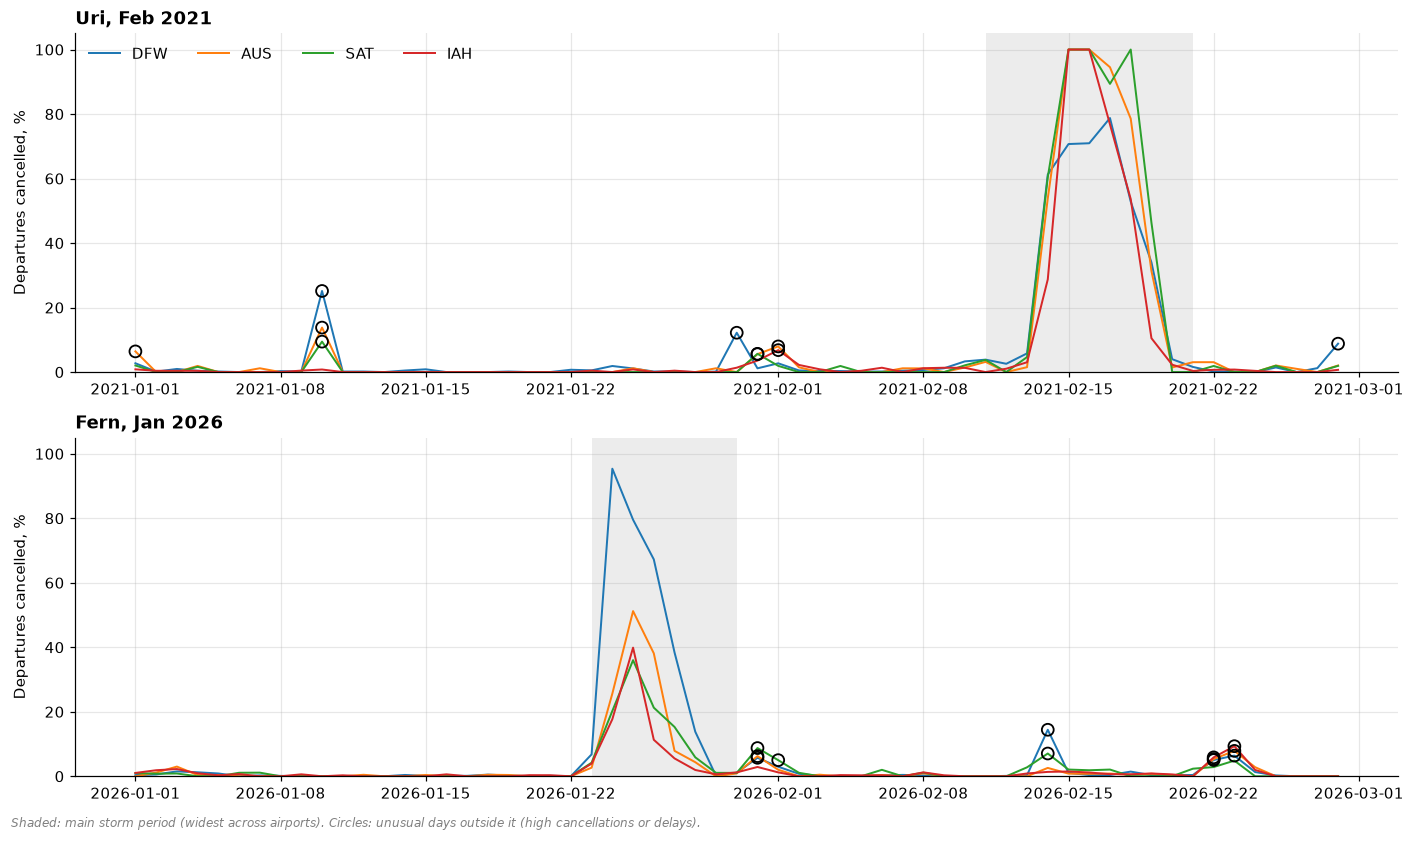

In [83]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
for ax, (event_id, label) in zip(axes, EVENTS.items()):
    event_days = daily[daily["event_id"] == event_id]
    for airport in AIRPORTS:
        data = event_days[event_days["airport_code"] == airport].sort_values("day")
        ax.plot(data["day"], data["cancel_rate"] * 100, label=airport, linewidth=1.3)
    storm = bounds[bounds["event_id"] == event_id]
    ax.axvspan(storm["storm_first_day"].min(), storm["storm_last_day"].max() + pd.Timedelta(days=1),
               color="grey", alpha=0.15, linewidth=0)
    unusual = flagged[flagged["event_id"] == event_id]
    ax.scatter(unusual["day"], unusual["cancel_rate"] * 100, s=60, facecolors="none",
               edgecolors="black", linewidths=1.2, zorder=3)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Departures cancelled, %")
    ax.set_title(label, loc="left", fontweight="bold")
axes[0].legend(frameon=False, ncol=4, loc="upper left")
fig.text(0.01, -0.01, "Shaded: main storm period (widest across airports). Circles: unusual days "
         "outside it (high cancellations or delays).", fontsize=8, color="grey", style="italic")
fig.tight_layout()
save(fig, "unusual_days.png")
plt.show()

### 8.2 What happened on the unusual days?

Weather details for each unusual day from the hourly METAR data (thunder, wind gusts,
visibility), and how many flights *to* the airport were diverted elsewhere compared with a
normal day. Diverted arrivals come from `prep_flights`, the only model that keeps arrivals.

In [84]:
weather_days = query('''
    SELECT airport_code,
           date_trunc('day', weather_hour)              AS day,
           count(*) FILTER (WHERE has_thunder)          AS thunder_hours,
           count(*) FILTER (WHERE has_rain)             AS rain_hours,
           count(*) FILTER (WHERE has_winter_precip)    AS winter_hours,
           max(wind_gust_max_kmh)                       AS max_gust_kmh,
           min(visibility_min_km)                       AS min_visibility_km
    FROM prep_weather_hourly
    GROUP BY ALL
''')

arrivals = query('''
    SELECT dest_airport                                 AS airport_code,
           date_trunc('day', scheduled_arr_ts)          AS day,
           count(*)                                     AS arrivals,
           count(*) FILTER (WHERE is_diverted)          AS diverted_arrivals
    FROM prep_flights
    WHERE is_arrival AND scheduled_arr_ts IS NOT NULL
    GROUP BY ALL
''')
arrivals["year"] = arrivals["day"].dt.year
normal_diversions = (arrivals.groupby(["airport_code", "year"], as_index=False)["diverted_arrivals"]
                     .median().rename(columns={"diverted_arrivals": "normal_diverted_arrivals"}))
arrivals = arrivals.merge(normal_diversions, on=["airport_code", "year"])

details = (flagged[["storm", "airport_code", "day", "date", "cancel_rate", "main_cancel_reason"]]
           .merge(weather_days, on=["airport_code", "day"], how="left")
           .merge(arrivals[["airport_code", "day", "arrivals", "diverted_arrivals",
                            "normal_diverted_arrivals"]], on=["airport_code", "day"], how="left"))

def explain(row) -> str:
    if row["winter_hours"] > 0:
        return "local snow or ice"
    if row["thunder_hours"] > 0:
        return "local thunderstorms"
    return "weather elsewhere in the network"


details["explanation"] = details.apply(explain, axis=1)

details.drop(columns="day").set_index(["storm", "airport_code", "date"]).style.format({
    "cancel_rate": "{:.0%}",
    "thunder_hours": "{:.0f}",
    "rain_hours": "{:.0f}",
    "winter_hours": "{:.0f}",
    "max_gust_kmh": "{:.0f}",
    "min_visibility_km": "{:.1f}",
    "arrivals": "{:.0f}",
    "diverted_arrivals": "{:.0f}",
    "normal_diverted_arrivals": "{:.0f}",
}, na_rep="—")

**Result.** The unusual days fall into three groups:

- **Local snow or ice outside the main storm:** 10 January 2021 at DFW, AUS and SAT, a one-day
  snowfall a month before Uri. DFW cancelled a quarter of its departures.
- **Local thunderstorms:** 30 January 2021, 28 February 2021 and 14 February 2026 at DFW. These
  are the only days with many diverted arrivals (31–48, against none on a normal day). This
  explains the diversion spike on 28 February 2021 noticed in the original project: a
  thunderstorm at the airport with gusts up to 54 km/h, not a winter event.
- **Weather elsewhere in the network:** all other days. There was no precipitation or thunder at
  the airport, yet airlines attributed the cancellations to weather: aircraft and crews were held
  up by storms in other parts of the country, for example the Northeast blizzard of
  31 January – 2 February 2021.

### 8.3 Anomalies in the data itself

Some values looked wrong while building the pipeline. They are kept here as examples of why
the data was checked rather than trusted.

In [85]:
cancelled_but_delayed = query('''
    SELECT event_id,
           count(*) FILTER (WHERE is_cancelled)                          AS cancelled,
           count(*) FILTER (WHERE is_cancelled AND dep_delay_min >= 15)  AS cancelled_with_delay
    FROM mart_flights_weather
    GROUP BY ALL
''')
cancelled_but_delayed["storm"] = cancelled_but_delayed["event_id"].map(EVENTS)
print("Cancelled flights that also report a departure delay of 15+ minutes:")
print(cancelled_but_delayed[["storm", "cancelled", "cancelled_with_delay"]].to_string(index=False), "\n")

heavy_gauge = query('''
    SELECT airport_code, weather_hour, precip_mm, weather_codes_hour, temp_c
    FROM prep_weather_hourly
    WHERE precip_mm >= 20
    ORDER BY precip_mm DESC
''')
print("Hours with 20+ mm of precipitation:")
print(heavy_gauge.to_string(index=False))

Cancelled flights that also report a departure delay of 15+ minutes:
         storm  cancelled  cancelled_with_delay
Fern, Jan 2026       3585                    46
 Uri, Feb 2021       4674                    26 

Hours with 20+ mm of precipitation:
airport_code        weather_hour  precip_mm weather_codes_hour  temp_c
         DFW 2026-01-24 21:00:00      43.18   PL BR | PL | +PL    -7.8
         DFW 2026-01-24 18:00:00      30.48         PL BR | PL    -7.2
         DFW 2026-01-24 22:00:00      30.48              -SNPL    -8.3
         DFW 2026-01-25 00:00:00      28.45     -SNPL BR | -SN    -8.3
         DFW 2026-01-24 19:00:00      22.35              -SNPL    -7.2
         DFW 2026-01-24 23:00:00      22.10   -SNPL | -SNPL BR    -8.9


- **Cancelled but delayed:** 26 of 4,674 cancelled flights in 2021 and 46 of 3,585 in 2026
  report a departure delay of 15+ minutes: they left the gate, for example for de-icing, and
  were cancelled afterwards. A dbt consistency test caught them; only operated flights count
  as delayed.
- **Precipitation gauge in ice pellets:** during Fern the DFW gauge reported 22–43 mm per hour
  for six hours in a row, about 177 mm in total, while ice pellets and light snow fell at
  −7 to −9 °C. Ice pellets cannot produce that much; 43 mm in an hour is a heavy summer
  downpour. Gauges are unreliable in freezing precipitation, so storm timing in this project is
  based on weather codes, not on precipitation amounts.

## Notes for interpretation

**Comparing the storms**
- Fern was much weaker than Uri at AUS, SAT and IAH (13, 14 and 3 winter hours against
  19–37 during Uri), so lower cancellation rates there partly reflect milder weather. DFW, with
  about 35 winter hours in both storms, is the fair comparison, and several metrics could only
  be compared there.
- After Uri, Texas had days of extreme cold and a power grid failure, which also slowed recovery;
  recovery time is not only a measure of airport or airline preparedness.
- 2021 traffic was reduced by COVID-19, so the analysis compares rates, not counts.
- Rates based on few departures or few hours are hidden (shown as n/a or —); the thresholds are
  stated in each section.

**Flights**
- Flights are matched to the weather of their **scheduled** departure hour, because cancelled
  flights have no actual departure. A long delay in a winter hour means the flight left later,
  often after the precipitation had ended.
- Taxi-out time includes waiting for aircraft de-icing, which is done by the airlines, so it
  reflects airports and airlines together.
- BTS reports the operating carrier; regional carriers are grouped with the brand they fly for
  where that brand is unambiguous. Southwest serves Dallas and Houston mainly from Love Field and
  Hobby, which are not part of this project.
- Cancellation reasons are reported by the airlines themselves and are almost always "weather",
  including weather elsewhere in their network, so they do not separate local conditions from
  network effects.

**Weather**
- Weather comes from one METAR station per airport. METAR codes describe precipitation that is
  falling, not snow or ice lying on runways: most cancellations in both storms fell in hours
  without falling precipitation, before the storm or after it.
- Precipitation amounts from airport gauges are unreliable in freezing precipitation (section
  8.3), so storm timing is based on weather codes.
- Information on airport snow and ice equipment comes from the airports' own announcements.